In [1]:
%matplotlib inline
import datacube, numpy as np, pandas as pd, matplotlib.pyplot as plt
import geopandas as gpd
from odc.geo.geom import Geometry
from deafrica_tools.datahandling import load_ard
from deafrica_tools.bandindices import calculate_indices
from deafrica_tools.areaofinterest import define_area

In [2]:
dc = datacube.Datacube(app="task1")

In [3]:
lat = 7.31112
lon = -1.57730
buffer = 0.04
date = '2020-08-01'

In [4]:
# Study area (same one you'll reuse in Tasks 2-4)
aoi = define_area(lat, lon, buffer)
geom = Geometry(aoi["features"][0]["geometry"], crs="epsg:4326")
gdf = gpd.GeoDataFrame(geometry=[geom], crs=geom.crs)
lon_range = (gdf.total_bounds[0], gdf.total_bounds[2])
lat_range = (gdf.total_bounds[1], gdf.total_bounds[3])



In [5]:
query = dict(x=lon_range, y=lat_range,
             time=("2019-01-01", "2023-12-31"),
             resolution=(-10, 10), output_crs="EPSG:6933")

ds = load_ard(dc=dc, products=["s2_l2a"],
              measurements=["red", "green", "blue", "nir"],
              min_gooddata=0.7, group_by="solar_day", **query)

# Both indices from the same images
ds = calculate_indices(ds, index=["NDVI", "EVI"], satellite_mission="s2")

# Keep cropland pixels only
cm = dc.load(product="crop_mask", time=("2019"), measurements="filtered",
             resampling="nearest", like=ds.geobox).filtered.squeeze()
ds = ds.where(cm == 1)

Using pixel quality parameters for Sentinel 2
Finding datasets
    s2_l2a
Counting good quality pixels for each time step


/opt/venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


Filtering to 141 out of 361 time steps with at least 70.0% good quality pixels
Applying pixel quality/cloud mask
Loading 141 time steps


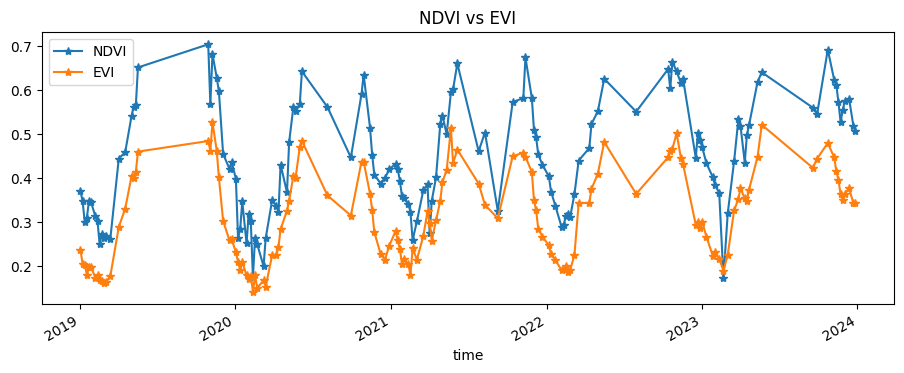

In [7]:
# Average NDVI and EVI over the whole area for each date
ts = ds[['NDVI', 'EVI']].mean(['x', 'y']).to_dataframe()[['NDVI', 'EVI']].dropna()

# Plot both on one graph
ts.plot(figsize=(11, 4), marker='*')
plt.title('NDVI vs EVI');

In [8]:
# Table: highest, lowest and average value, and when the highest happened
table = pd.DataFrame({
    'Peak value': ts.max(),
    'Date of peak': ts.idxmax(),
    'Lowest value': ts.min(),
    'Average': ts.mean()
})
table

,Peak value,Date of peak,Lowest value,Average
NDVI,0.703410,2019-10-29 10:39:00,0.173980,0.449771
EVI,0.526926,2019-11-08 10:38:59,0.142832,0.312980


In [13]:
grow = ts[(ts.index.month >= 5) & (ts.index.month <= 11)]
lowest = grow.nsmallest(5, 'NDVI')
avg = grow['NDVI'].mean()
lowest['% below avg'] = ((avg - lowest['NDVI']) / avg * 100).round(1)
lowest

,NDVI,EVI,% below avg
time,,,
2021-09-08 10:38:56,0.325926,0.309045,43.099998
2020-05-01 10:39:03,0.367550,0.326461,35.799999
2020-11-22 10:39:00,0.407956,0.277588,28.700001
2020-09-28 10:39:05,0.446917,0.315290,21.900000
2020-11-17 10:39:03,0.452802,0.328362,20.900000


## Findings

The lowest growing-season NDVI values fell at the edges of the seasons, such as 1 May 2020 (0.37) and mid to late November 2020 (0.41 to 0.45), when fields are being planted or harvested, so these are not interpreted as stress. The clearest mid-season dip was on 8 September 2021, when NDVI fell to 0.33 and EVI to 0.31, 43% below the growing-season average. A smaller dip occurred on 28 September 2020 (22% below average). 
The September 2021 NDVI dip occurred during the wettest month of the year (295 mm, well above the monthly average), so it is unlikely to reflect drought stress. It may instead be the normal gap between the two seasons, residual cloud contamination in optical images during heavy rain, or waterlogging.
Peak greenness stayed fairly consistent across years (NDVI about 0.62 to 0.70), so no severe multi-season drought is evident in this area for 2019 to 2023.